### juvenile_ESN_ver2

Contains small edits and improvements to original 'juvenile_ESN' notebook 
- Understanding how to split the data into training and testing   

Tested against the Logistic Map toy system 

--- Date:    March 2026

In [21]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(123)

def logistic_map(r,x0,iterations):
    # r: parameter value
    #x0: starting value
    #iterations: number of vals 

    x=np.zeros(iterations)
    x[0] = x0

    for k in range(iterations-1):
        
        x[k+1] = r * x[k] * (1-x[k])
    return x


In [22]:
# p = spectral radius
p = 1.1
d = 5 # average connections per neuron
N = 10 # number of nodes 

# creating the weight matrix - identity matrix of 10x10
Vadj = np.multiply(
    np.random.binomial(size=(N,N), p=d/N, n=1),
    np.random.normal(size=(N,N)))

# multiply by spectral radius to control stability and memory
Vadj = Vadj * (p/np.max(np.absolute(np.linalg.eig(Vadj)[0])))

#creating random input weights 
Vin = np.random.uniform(-1,1,size=(N,1))

#creating bias vector (Nx number of obs)
Vbias = np.random.uniform(-1,1,size=(N,))


In [23]:
example = logistic_map(4,0.1,500)
print(len(example))

#initial reservoir state 
x = np.zeros(N)

#reservoir states
states = np.zeros((len(example), N))

for i in range(len(example)):
    x = np.tanh(np.matmul(Vadj, x) + np.matmul(Vin,[example[i]]) + Vbias)
    states[i] = x


500


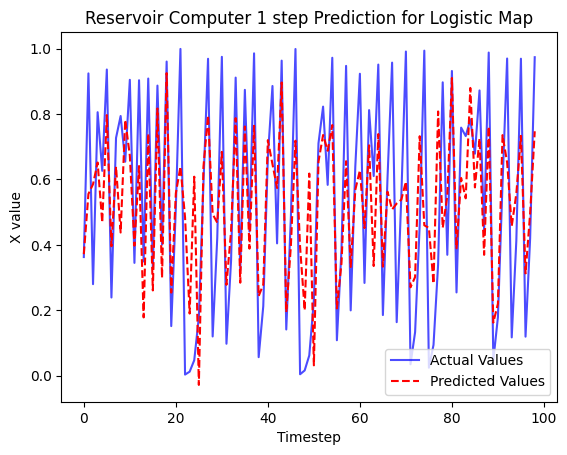

In [24]:
#training the reservoir computer
t_train = 400
t_test = 100

x_train = states[:t_train-1] #x-values for training 
y_train = example[1:t_train] #y-values for training
x_test = states[t_train:-1] #x-values for testing
y_test = example[t_train+1:]


least_squares = np.linalg.lstsq(x_train,y_train,rcond=None)[0]
#lstsq will return solution, residuals, rank, singular_vals
Vout = least_squares

Y_predicted = np.matmul(x_test, Vout)


plt.plot(y_test, label = 'Actual Values',color='blue', alpha=0.7)
plt.plot(Y_predicted, label='Predicted Values',color='red', linestyle='dashed')
plt.xlabel('Timestep')
plt.ylabel('X value')
plt.legend()
plt.title('Reservoir Computer 1 step Prediction for Logistic Map')
plt.savefig('FirstOutput.png')
